Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Extracting /content/archive.zip...
Detected Flower Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/flowers_yolo_cls, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False

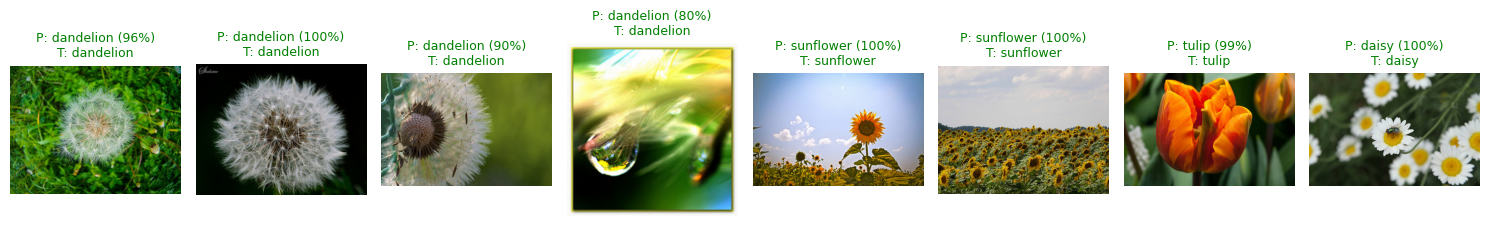

In [1]:
import os
import time
import glob
import shutil
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

start_time = time.time()
random.seed(42)
np.random.seed(42)

# Install ultralytics if not already installed
try:
    from ultralytics import YOLO
except ImportError:
    !pip install -q ultralytics
    from ultralytics import YOLO

# ---------------------------------------------------------
# 1. EXTRACT & PREPARE YOLO CLASSIFICATION DATASET (train/val)
# ---------------------------------------------------------
zip_matches = glob.glob('/content/**/*.zip', recursive=True)
assert len(zip_matches) > 0, "Please upload the flowers dataset .zip file to Colab Files first!"

raw_extract = '/content/flowers_raw'
if not os.path.exists(raw_extract):
    print(f"Extracting {zip_matches[0]}...")
    with zipfile.ZipFile(zip_matches[0], 'r') as z:
        z.extractall(raw_extract)

# Find the directory containing flower class subfolders
best_dir = raw_extract
max_classes = 0
valid_exts = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

for root, dirs, _ in os.walk(raw_extract):
    class_dirs = []
    for d in dirs:
        imgs = [
            f for f in glob.glob(os.path.join(root, d, '*'))
            if os.path.splitext(f)[1].lower() in valid_exts
        ]
        if len(imgs) >= 10:
            class_dirs.append(d)
    if len(class_dirs) > max_classes:
        max_classes = len(class_dirs)
        best_dir = root

class_names = sorted([
    d for d in os.listdir(best_dir)
    if os.path.isdir(os.path.join(best_dir, d)) and len([
        f for f in glob.glob(os.path.join(best_dir, d, '*'))
        if os.path.splitext(f)[1].lower() in valid_exts
    ]) >= 10
])
assert len(class_names) >= 2, "Could not find flower class folders in extracted dataset."
print("Detected Flower Classes:", class_names)

# Build a fast, balanced subset (~240 train + ~60 val per class -> ~1,500 images total)
# Keeps CPU training fast (< 2 min) while giving high accuracy
yolo_data_dir = '/content/flowers_yolo_cls'
if os.path.exists(yolo_data_dir):
    shutil.rmtree(yolo_data_dir)

val_samples = []  # Keep track of (image_path, true_class) for visualization

for cname in class_names:
    src_files = [
        f for f in glob.glob(os.path.join(best_dir, cname, '*'))
        if os.path.splitext(f)[1].lower() in valid_exts
    ]
    random.shuffle(src_files)

    n_val = min(60, max(10, int(0.15 * len(src_files))))
    n_train = min(240, max(20, len(src_files) - n_val))

    selected_val = src_files[:n_val]
    selected_train = src_files[n_val:n_val + n_train]

    train_out = os.path.join(yolo_data_dir, 'train', cname)
    val_out = os.path.join(yolo_data_dir, 'val', cname)
    os.makedirs(train_out, exist_ok=True)
    os.makedirs(val_out, exist_ok=True)

    for idx, src in enumerate(selected_train):
        ext = os.path.splitext(src)[1].lower()
        shutil.copy2(src, os.path.join(train_out, f"{cname}_{idx}{ext}"))

    for idx, src in enumerate(selected_val):
        ext = os.path.splitext(src)[1].lower()
        dst = os.path.join(val_out, f"{cname}_{idx}{ext}")
        shutil.copy2(src, dst)
        val_samples.append((dst, cname))

# ---------------------------------------------------------
# 2. TRAIN PRETRAINED YOLO CLASSIFIER ON CPU
# ---------------------------------------------------------
model = YOLO('yolo11n-cls.pt')  # Nano classification model — fast on CPU & high accuracy

results = model.train(
    data=yolo_data_dir,
    epochs=5,
    imgsz=128,
    batch=32,
    device='cpu',
    workers=2,
    project='/content/runs',
    name='flowers_cpu',
    exist_ok=True,
    verbose=True
)

metrics = model.val(data=yolo_data_dir, imgsz=128, batch=32, device='cpu', verbose=False)
top1_acc = float(metrics.top1) * 100.0
elapsed = time.time() - start_time

print(f"\nValidation Top-1 Accuracy: {top1_acc:.2f}%")
print(f"Total Execution Time: {elapsed:.1f} seconds")

# ---------------------------------------------------------
# 3. VISUALIZE SAMPLE PREDICTIONS (P = Predicted, T = True)
# ---------------------------------------------------------
random.shuffle(val_samples)
show_items = val_samples[:8]
show_paths = [p for p, _ in show_items]
true_labels = [t for _, t in show_items]

preds = model.predict(source=show_paths, imgsz=128, device='cpu', verbose=False)

plt.figure(figsize=(15, 4))
for i, (img_path, true_cls) in enumerate(zip(show_paths, true_labels)):
    pred_idx = int(preds[i].probs.top1)
    pred_cls = preds[i].names[pred_idx]
    conf = float(preds[i].probs.top1conf) * 100.0

    img = Image.open(img_path).convert('RGB')
    plt.subplot(1, len(show_paths), i + 1)
    plt.imshow(img)
    matched = pred_cls.lower() == true_cls.lower()
    plt.title(
        f"P: {pred_cls} ({conf:.0f}%)\nT: {true_cls}",
        color='green' if matched else 'red',
        fontsize=9
    )
    plt.axis('off')

plt.tight_layout()
plt.show()